# Diagnostics for the instellation sweep

Plots made from the saved results of `archean_instellation_sweep.ipynb` (the JSON files in `sweep_results/`). Nothing is re-simulated here, so the notebook runs in seconds with just NumPy and Matplotlib.

Each simulation point is one star at one instellation, with the CO₂ pressure adjusted so the coupled climate–photochemistry model holds 288 K. The figures are:

1. **CO₂ needed to hold 288 K**, and how much less the M dwarf (GJ 876) needs than the Sun.
2. **Where GJ 876 has no steady state**: every coupling iteration plotted by CO₂ pressure, which shows that the runaway is set by CO₂ pressure and not by instellation.
3. **The reduced gases** (H₂, CH₄, CO) that the photochemistry produces and that feed back on the climate.
4. **Solver diagnostics**: coupling iterations, how far the surface temperature ends up from 288 K, and the compute cost per point.

**Marker key (used in every figure).** Colour identifies the star. Marker shape gives the state of the point: a filled circle holds 288 K with a steady-state atmosphere; an open circle is steady but 288 K was not reachable (the model used the CO₂ giving the warmest surface, up to a 10 bar cap); a cross has no steady state (hydrocarbons accumulate without bound because this chemistry has no haze sink), so its composition is not meaningful. Where both stars have a point at the same instellation, the markers are shifted sideways by ±5 W/m² so that neither hides the other.

In [1]:
import glob, json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ---- load the saved results -------------------------------------------------
results = []
for path in sorted(glob.glob("sweep_results/*.json")):
    results.append(json.load(open(path)))
results.sort(key=lambda r: (r["star"], -r["S_Wm2"]))

def state(r):
    if r["photochem_stop"].startswith("runaway"):
        return "runaway"
    if r["target_status"] != "ok" or abs(r["T_surf_K"] - 288.0) > 1.5:
        return "unreached"
    return "holds"

stars = ["Sun", "GJ876"]
by_star = {s: [r for r in results if r["star"] == s] for s in stars}
print({s: len(v) for s, v in by_star.items()}, "points;",
      {st: sum(state(r) == st for r in results) for st in ("holds", "unreached", "runaway")})

# ---- look: validated categorical slots 1 (blue) and 2 (orange); ink and grid tokens ----
COLOR = {"Sun": "#2a78d6", "GJ876": "#eb6834"}
NAME = {"Sun": "Sun (3 Ga spectrum)", "GJ876": "GJ 876 (M dwarf)"}
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e7e6e2"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "regular", "axes.titlelocation": "left",
    "axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9, "font.size": 10,
    "lines.linewidth": 2, "legend.frameon": False, "legend.fontsize": 9,
})

DODGE = {"Sun": 5.0, "GJ876": -5.0}      # W/m^2, so coincident points of the two stars stay visible

def draw(ax, star, S, y, states, line=True, size=8, label=None):
    # One line per star through the points that have data; marker shape = state.
    S, y = np.asarray(S, float) + DODGE[star], np.asarray(y, float)
    keep = np.array([s != "runaway" for s in states]) if line else np.ones(len(S), bool)
    if line and keep.sum() > 1:
        ax.plot(S[keep], y[keep], "-", color=COLOR[star], lw=2, alpha=0.55, zorder=2)
    for stt, mk, filled in (("holds", "o", True), ("unreached", "o", False), ("runaway", "X", True)):
        sel = np.array([s == stt for s in states])
        if not sel.any(): continue
        is_x = stt == "runaway"
        ax.plot(S[sel], y[sel], mk, ms=size + (1 if is_x else 0), ls="none", zorder=3,
                mfc=COLOR[star] if filled else SURFACE, mec=COLOR[star] if (is_x or not filled) else SURFACE,
                mew=1.5)
    if label:                                   # direct label at the first point that has a steady state
        i = next((k for k, s_ in enumerate(states) if s_ != "runaway"), None)
        if i is not None:
            ax.annotate(label, (S[i], y[i]), textcoords="offset points", xytext=(9, 7), color=INK, fontsize=9)

def key_handles():
    h = [Line2D([], [], marker="o", ls="none", ms=8, mfc=COLOR[s], mec=SURFACE, mew=1.5, label=NAME[s]) for s in stars]
    h += [Line2D([], [], marker="o", ls="none", ms=8, mfc=INK2, mec=SURFACE, mew=1.5, label="holds 288 K, steady"),
          Line2D([], [], marker="o", ls="none", ms=8, mfc=SURFACE, mec=INK2, mew=2, label="steady, 288 K not reachable"),
          Line2D([], [], marker="X", ls="none", ms=9, mfc=INK2, mec=INK2, mew=1.5, label="no steady state")]
    return h

def finish(fig, axes, fname):
    for ax in np.atleast_1d(axes).ravel():
        ax.invert_xaxis(); ax.set_xlabel("Instellation (W m$^{-2}$)")
    fig.tight_layout(rect=(0, 0.09, 1, 1))
    fig.legend(handles=key_handles(), loc="lower center", ncol=5, bbox_to_anchor=(0.5, 0.0))
    fig.savefig(f"diagnostic_plots/{fname}.png", dpi=150, bbox_inches="tight")
    plt.show()

import os; os.makedirs("diagnostic_plots", exist_ok=True)

{'Sun': 17, 'GJ876': 20} points; {'holds': 24, 'unreached': 6, 'runaway': 7}


## 1. CO₂ needed to hold 288 K

Left: the CO₂ partial pressure the solver ended up with at each instellation. Right: the ratio of the Sun's value to GJ 876's at the instellations where both hold 288 K in a steady state (above 1 means GJ 876 needs less CO₂). The crosses on the left are the CO₂ pressures the solver *attempted* at points with no steady state; they are not values that hold 288 K.

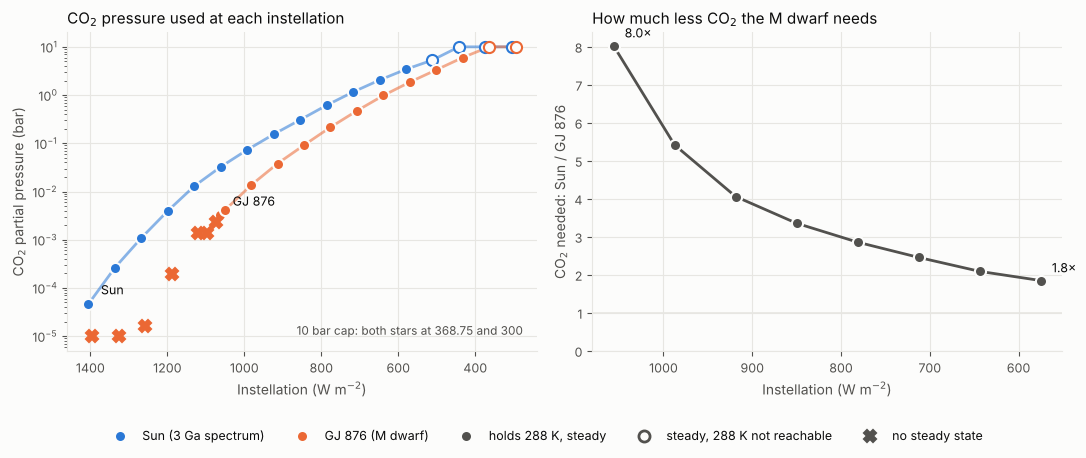

Ratio over 8 common points: 1.8x to 8.0x


In [2]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.6))
for s in stars:
    rs = by_star[s]
    draw(a1, s, [r["S_Wm2"] for r in rs], [r["pCO2_bar"] for r in rs], [state(r) for r in rs], label=NAME[s].split(" (")[0])
a1.set_yscale("log"); a1.set_ylabel("CO$_2$ partial pressure (bar)")
a1.set_title("CO$_2$ pressure used at each instellation")
a1.text(0.97, 0.05, "10 bar cap: both stars at 368.75 and 300", transform=a1.transAxes, ha="right", color=INK2, fontsize=8.5)

# ratio Sun / GJ 876 where both hold 288 K
sun = {r["S_Wm2"]: r for r in by_star["Sun"] if state(r) == "holds"}
gj = {r["S_Wm2"]: r for r in by_star["GJ876"] if state(r) == "holds"}
common = sorted(set(sun) & set(gj), reverse=True)
ratio = [sun[S]["pCO2_bar"] / gj[S]["pCO2_bar"] for S in common]
a2.plot(common, ratio, "-o", color=INK2, lw=2, ms=8, mec=SURFACE, mew=1.5)
a2.axhline(1, color=GRID, lw=1.2, zorder=1)
a2.set_ylabel("CO$_2$ needed: Sun / GJ 876"); a2.set_ylim(0, None)
a2.set_title("How much less CO$_2$ the M dwarf needs")
for S, q in ((common[0], ratio[0]), (common[-1], ratio[-1])):
    a2.annotate(f"{q:.1f}×", (S, q), textcoords="offset points", xytext=(8, 6), color=INK, fontsize=9)
finish(fig, (a1, a2), "fig1_co2_required")
print(f"Ratio over {len(common)} common points: {min(ratio):.1f}x to {max(ratio):.1f}x")

## 2. Where GJ 876 has no steady state

Every coupling iteration of every point, at the CO₂ pressure it was run with. For GJ 876, all steady iterations lie above a CO₂ pressure of a few ×10⁻³ bar and all runaway iterations lie below it, whatever the instellation. The Sun is steady at every CO₂ pressure it was run with, including much lower ones, so the runaway is specific to the M dwarf spectrum.

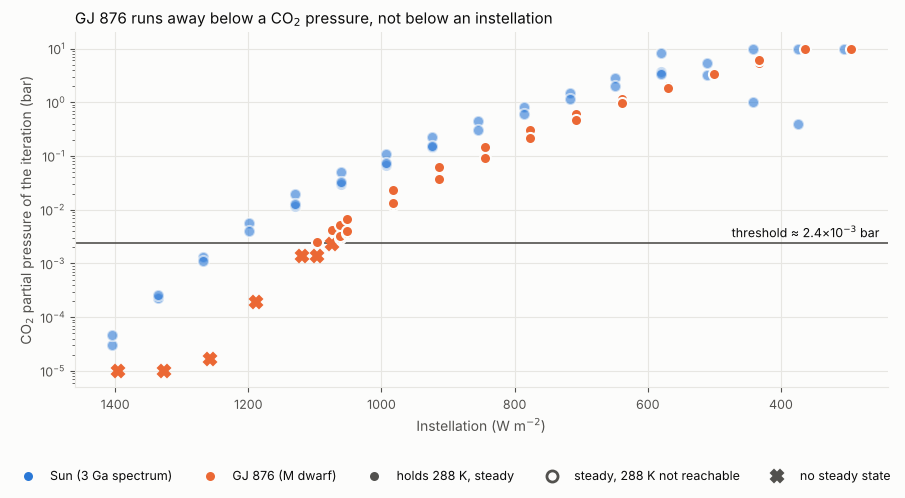

GJ 876: 29 steady iterations (min CO2 2.50e-03 bar), 7 runaway iterations (max CO2 2.28e-03 bar)
Sun: 38 iterations, none runaway; lowest CO2 3.1e-05 bar


In [3]:
fig, ax = plt.subplots(figsize=(9, 5.0))
steady_p, run_p = [], []
for s in stars:
    for r in by_star[s]:
        for h in r["history"]:
            run = h["photochem_stop"].startswith("runaway")
            (run_p if (run and s == "GJ876") else steady_p if s == "GJ876" else []).append(h["pCO2_bar"])
            ax.plot(r["S_Wm2"] + DODGE[s], h["pCO2_bar"], "X" if run else "o", ms=9 if run else 8, ls="none", zorder=3,
                    mfc=COLOR[s], mec=COLOR[s] if run else SURFACE, mew=1.5, alpha=1.0 if s == "GJ876" else 0.6)
threshold = 0.5 * (min(steady_p) + max(run_p))
ax.axhline(threshold, color=INK2, lw=1.2, zorder=2)
mant, exp = f"{threshold:.1e}".split("e")
ax.text(0.99, threshold * 1.12, f"threshold ≈ {mant}×10$^{{{int(exp)}}}$ bar",
        transform=ax.get_yaxis_transform(), ha="right", va="bottom", color=INK, fontsize=9)
ax.set_yscale("log"); ax.set_ylabel("CO$_2$ partial pressure of the iteration (bar)")
ax.set_title("GJ 876 runs away below a CO$_2$ pressure, not below an instellation")
finish(fig, ax, "fig2_runaway_threshold")
print(f"GJ 876: {len(steady_p)} steady iterations (min CO2 {min(steady_p):.2e} bar), "
      f"{len(run_p)} runaway iterations (max CO2 {max(run_p):.2e} bar)")
print(f"Sun: {sum(len(r['history']) for r in by_star['Sun'])} iterations, none runaway; lowest CO2 "
      f"{min(h['pCO2_bar'] for r in by_star['Sun'] for h in r['history']):.1e} bar")

## 3. The reduced gases

Surface mixing ratios of H₂, CH₄ and CO at the points with a steady state. H₂ and CH₄ are the two photochemically-set gases that the climate model includes (so they feed back on the temperature); CO is not in the climate model but is the main carbon reservoir in the oxidant-poor cases. Crosses (no steady state) are omitted because their composition is not meaningful.

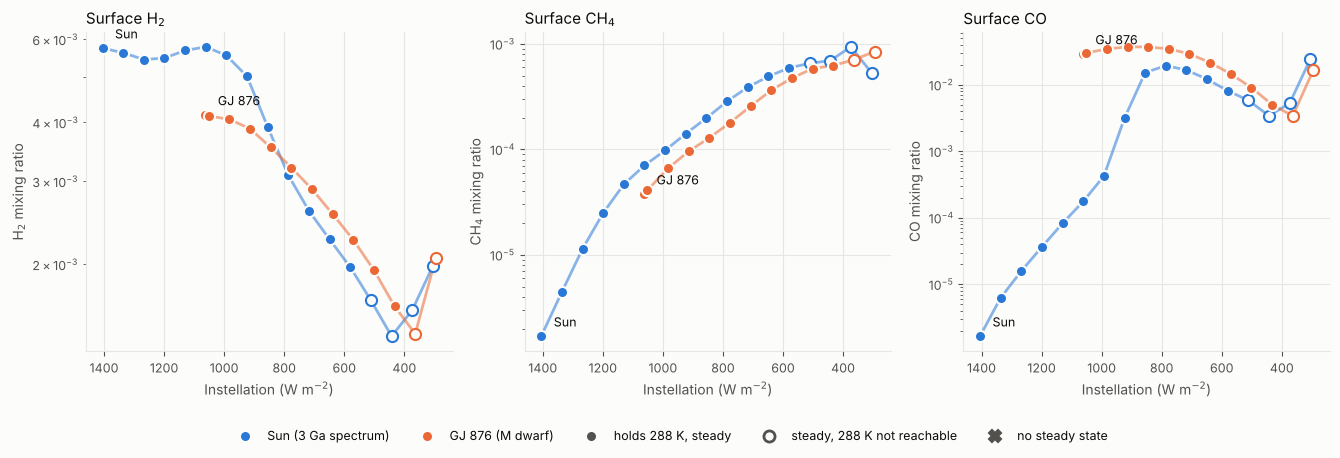

H2  Sun    (points that hold 288 K): 2.0e-03 to 5.8e-03
H2  GJ876  (points that hold 288 K): 1.6e-03 to 4.2e-03
CH4 Sun    (points that hold 288 K): 1.7e-06 to 5.9e-04
CH4 GJ876  (points that hold 288 K): 3.8e-05 to 6.2e-04
CO  Sun    (points that hold 288 K): 1.7e-06 to 1.9e-02
CO  GJ876  (points that hold 288 K): 5.0e-03 to 3.7e-02


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.6))
for ax, (gas, label) in zip(axes, (("H2", "H$_2$"), ("CH4", "CH$_4$"), ("CO", "CO"))):
    for s in stars:
        rs = [r for r in by_star[s] if state(r) != "runaway"]
        draw(ax, s, [r["S_Wm2"] for r in rs], [r["vmr"][gas] for r in rs], [state(r) for r in rs], label=NAME[s].split(" (")[0])
    ax.set_yscale("log"); ax.set_ylabel(f"{label} mixing ratio"); ax.set_title(f"Surface {label}")
finish(fig, axes, "fig3_reduced_gases")
for gas in ("H2", "CH4", "CO"):
    for s in stars:
        v = [r["vmr"][gas] for r in by_star[s] if state(r) == "holds"]
        print(f"{gas:3s} {s:6s} (points that hold 288 K): {min(v):.1e} to {max(v):.1e}")

## 4. Solver diagnostics

- **Coupling iterations** needed before the CO₂ pressure stopped changing by more than about 5%. A point with no steady state stops at the first iteration that runs away, so it shows 1 or 2.
- **Surface-temperature shortfall**: the final surface temperature minus the 288 K target. Points that hold 288 K sit within about ±1 K; the open circles show how far short the unreachable points fall. Points with no steady state are left out, because their temperature depends on a composition that is not steady.
- **Compute cost**: wall-clock time summed over the photochemistry solves for each point. These were run four at a time on four cores, and the machine was sometimes busier than at other times, so treat them as rough.

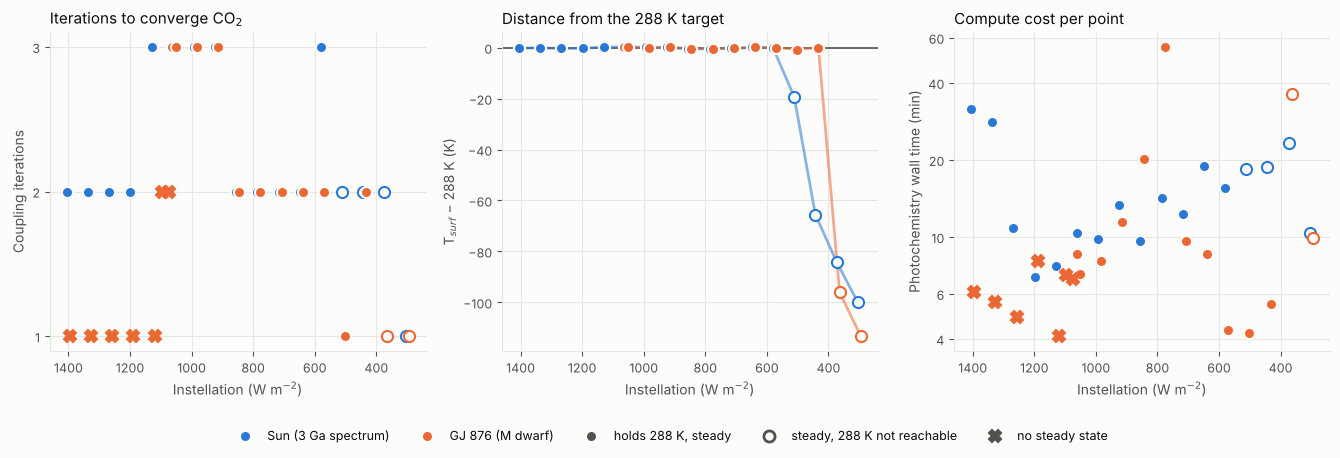

Total wall time summed over points (hours): Sun 5.0, GJ876 4.5


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.6))
for s in stars:
    rs = by_star[s]; S = [r["S_Wm2"] for r in rs]; st = [state(r) for r in rs]
    draw(axes[0], s, S, [r["iterations"] for r in rs], st, line=False)
    ok = [i for i, x in enumerate(st) if x != "runaway"]       # T_surf of a runaway point is not meaningful
    draw(axes[1], s, [S[i] for i in ok], [rs[i]["T_surf_K"] - 288.0 for i in ok], [st[i] for i in ok])
    draw(axes[2], s, S, [sum(h["photochem_wall_s"] for h in r["history"]) / 60.0 for r in rs], st, line=False)
axes[0].set_ylabel("Coupling iterations"); axes[0].set_title("Iterations to converge CO$_2$")
axes[0].yaxis.set_major_locator(plt.MaxNLocator(integer=True))
axes[1].set_ylabel("T$_{surf}$ − 288 K (K)"); axes[1].set_title("Distance from the 288 K target")
axes[1].axhline(0, color=INK2, lw=1.2, zorder=1)
axes[2].set_yscale("log"); axes[2].set_ylabel("Photochemistry wall time (min)"); axes[2].set_title("Compute cost per point")
axes[2].set_yticks([4, 6, 10, 20, 40, 60]); axes[2].set_yticklabels(["4", "6", "10", "20", "40", "60"]); axes[2].minorticks_off()
finish(fig, axes, "fig4_solver_diagnostics")
tot = {s: sum(r["wall_s"] for r in by_star[s]) / 3600 for s in stars}
print("Total wall time summed over points (hours): " + ", ".join(f"{s} {v:.1f}" for s, v in tot.items()))